# Review 2 Clustering - Raisin Morphology Profiles

**Problem:** Discover and compare groups of raisin morphology profiles using the seven image-derived numeric measurements in the UCI Raisin dataset.

**Required algorithms:** K-Means Clustering and Agglomerative Hierarchical Clustering.

**Label-free protocol:** `Class` is a supplied reference variety field. It is excluded from scaling, model fitting, k selection, linkage selection, PCA, and t-SNE. It is examined only after the clustering choices are frozen.

**Source:** [UCI Raisin Dataset](https://archive.ics.uci.edu/dataset/850/raisin), DOI [10.24432/C5660T](https://doi.org/10.24432/C5660T), CC BY 4.0.

> Team verification gate: Generative AI assisted with scaffolding. The team must rerun every cell, verify every output and interpretation, and be able to explain each line during the viva. The guideline says datasets are instructor-assigned, so this proposed source still requires instructor confirmation.

## 1. Reproducible setup and source loading

The tracked downloader validates the official outer archive and extracted ARFF hashes. The source label is retained separately but not inspected or passed to any unsupervised selection step.

In [1]:
from pathlib import Path
import hashlib
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy
import sklearn
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.io import arff
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


def find_repo_root() -> Path:
    candidates = (Path.cwd(), *Path.cwd().parents)
    for candidate in candidates:
        if (candidate / "requirements.txt").is_file() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the capstone repository.")


ROOT = find_repo_root()
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = ROOT / "data" / "raw" / "raisin" / "Raisin_Dataset.arff"
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Raisin data is missing. Run: python data/download_datasets.py --dataset clustering"
    )

records, source_metadata = arff.loadarff(DATA_PATH)
raw = pd.DataFrame(records)
raw["Class"] = raw["Class"].str.decode("utf-8")
REFERENCE_LABEL = "Class"
FEATURES = [column for column in raw.columns if column != REFERENCE_LABEL]
X_raw = raw[FEATURES].astype(float).copy()
y_reference = raw[REFERENCE_LABEL].copy()

print("Repository root detected.")
print(f"Python: {platform.python_version()}")
print(f"scikit-learn: {sklearn.__version__} | scipy: {scipy.__version__}")
print(f"Raw file: {DATA_PATH.relative_to(ROOT)}")
print(f"ARFF SHA-256: {hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()}")
print(f"Feature matrix: {X_raw.shape}; reference label excluded: {REFERENCE_LABEL}")
display(raw.head())

Repository root detected.
Python: 3.13.14
scikit-learn: 1.9.1 | scipy: 1.18.1
Raw file: data/raw/raisin/Raisin_Dataset.arff
ARFF SHA-256: 8a33803b5961650225150740fa09fa31ee8875266277c7ac3291e2a3ee351814
Feature matrix: (900, 7); reference label excluded: Class


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,"87,524.0000",442.2460,253.2912,0.8197,"90,546.0000",0.7587,"1,184.0400",Kecimen
1,"75,166.0000",406.6907,243.0324,0.8018,"78,789.0000",0.6841,"1,121.7860",Kecimen
2,"90,856.0000",442.2670,266.3283,0.7984,"93,717.0000",0.6376,"1,208.5750",Kecimen
3,"45,928.0000",286.5406,208.7600,0.6850,"47,336.0000",0.6996,844.1620,Kecimen
4,"79,408.0000",352.1908,290.8275,0.5640,"81,463.0000",0.7928,"1,073.2510",Kecimen


## 2. Source audit and label-free exploratory analysis

The audit checks the release directly. The reference column is excluded from every plot and statistic in this section, avoiding label-informed cluster decisions.

,dtype,missing,unique,minimum,maximum
Area,float64,0,900,"25,387.0000","235,047.0000"
MajorAxisLength,float64,0,900,225.6295,997.2919
MinorAxisLength,float64,0,900,143.7109,492.2753
Eccentricity,float64,0,900,0.3487,0.9621
ConvexArea,float64,0,896,"26,139.0000","278,217.0000"
Extent,float64,0,900,0.3799,0.8355
Perimeter,float64,0,900,619.0740,"2,697.7530"
Class,str,0,2,NaN,NaN


Missing values: 0
Exact duplicate rows: 0


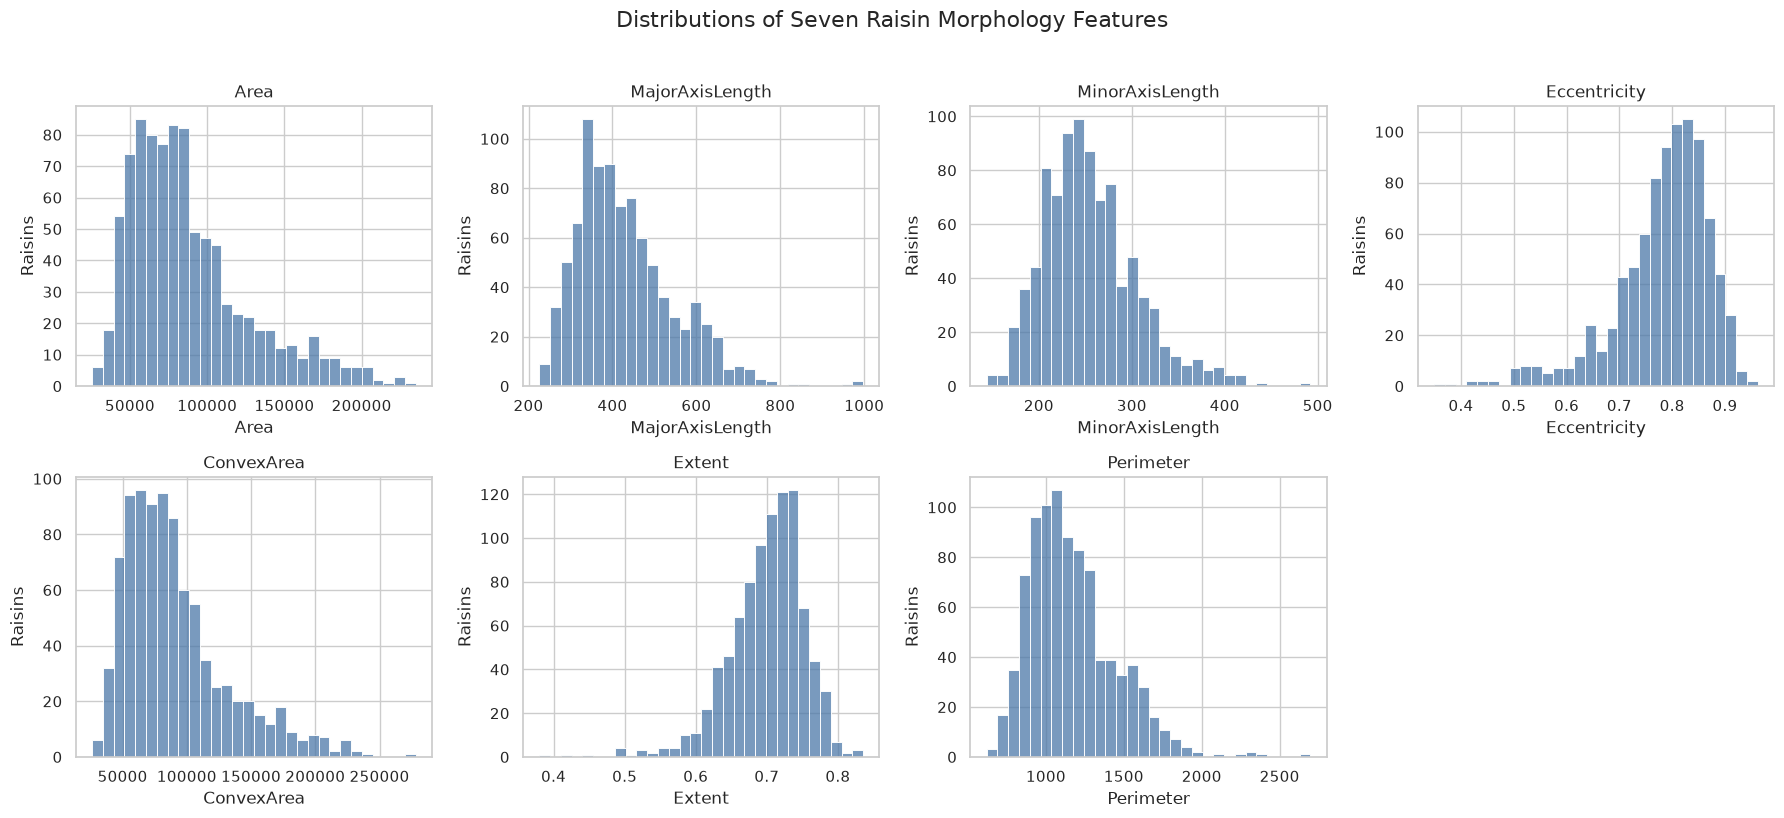

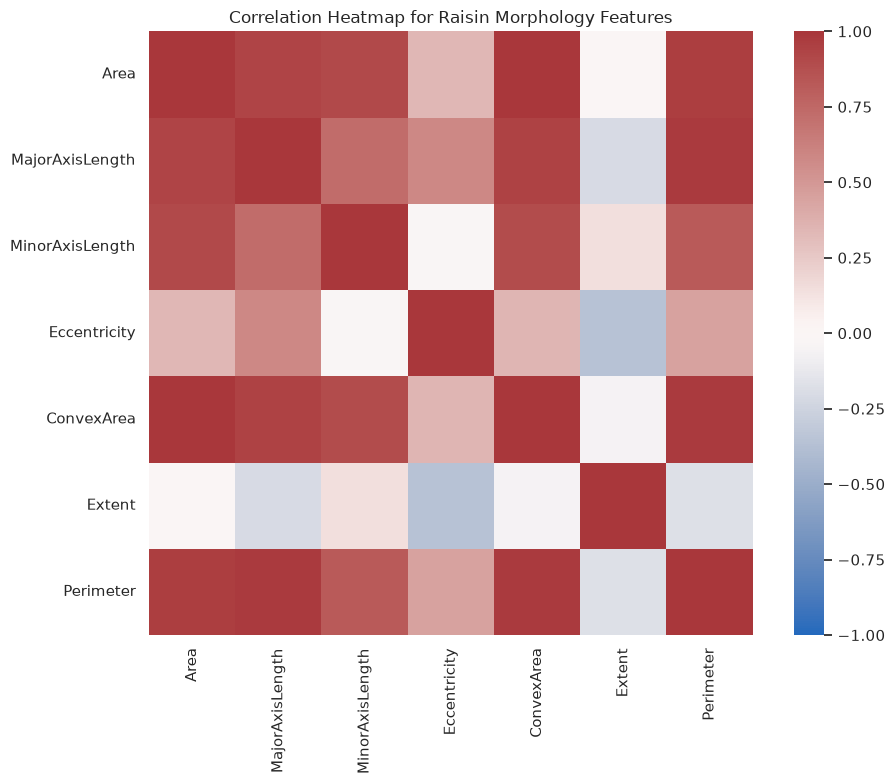

In [2]:
audit = pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "missing": raw.isna().sum(),
        "unique": raw.nunique(dropna=False),
        "minimum": X_raw.min().reindex(raw.columns),
        "maximum": X_raw.max().reindex(raw.columns),
    }
)
display(audit)
print(f"Missing values: {int(raw.isna().sum().sum())}")
print(f"Exact duplicate rows: {int(raw.duplicated().sum())}")
assert X_raw.shape == (900, 7)
assert X_raw.isna().sum().sum() == 0
assert raw.duplicated().sum() == 0

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for axis, column in zip(axes.flat, FEATURES):
    sns.histplot(X_raw[column], bins=30, color="#4C78A8", ax=axis)
    axis.set_title(column)
    axis.set_xlabel(column)
    axis.set_ylabel("Raisins")
axes.flat[-1].axis("off")
fig.suptitle("Distributions of Seven Raisin Morphology Features", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(X_raw.corr(), cmap="vlag", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation Heatmap for Raisin Morphology Features")
plt.tight_layout()
plt.show()

**Observation:** The verified release has 900 rows, seven numeric morphology features, no missing values, and no exact duplicates. Raw feature scales differ substantially, while size-related measurements are correlated. Euclidean-distance methods therefore require standardization; correlation alone is not grounds to remove a feature.

## 3. Standardization and K-Means candidate search

There is no supervised train/test split in this unsupervised track. `StandardScaler` is fitted to the complete unlabeled feature matrix. We predeclare k from 2 through 8 and choose the final k by the highest internal silhouette score. The Elbow, Davies-Bouldin, and Calinski-Harabasz diagnostics remain visible as complementary evidence.

,Feature,Scaled mean,Scaled standard deviation
0,Area,0.0000,1.0000
1,MajorAxisLength,0.0000,1.0000
2,MinorAxisLength,-0.0000,1.0000
3,Eccentricity,0.0000,1.0000
4,ConvexArea,0.0000,1.0000
5,Extent,0.0000,1.0000
6,Perimeter,-0.0000,1.0000


,k,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,2,3397.84,0.4411,0.9101,767.00
1,3,2591.65,0.3092,1.1009,641.76
2,4,2168.41,0.2950,1.0820,569.06
3,5,1895.93,0.2969,1.0992,519.75
4,6,1684.06,0.2735,1.0714,490.09
5,7,1493.54,0.2773,1.0074,479.00
6,8,1354.20,0.2620,1.0361,465.39


Selected k from the highest label-free silhouette: 2


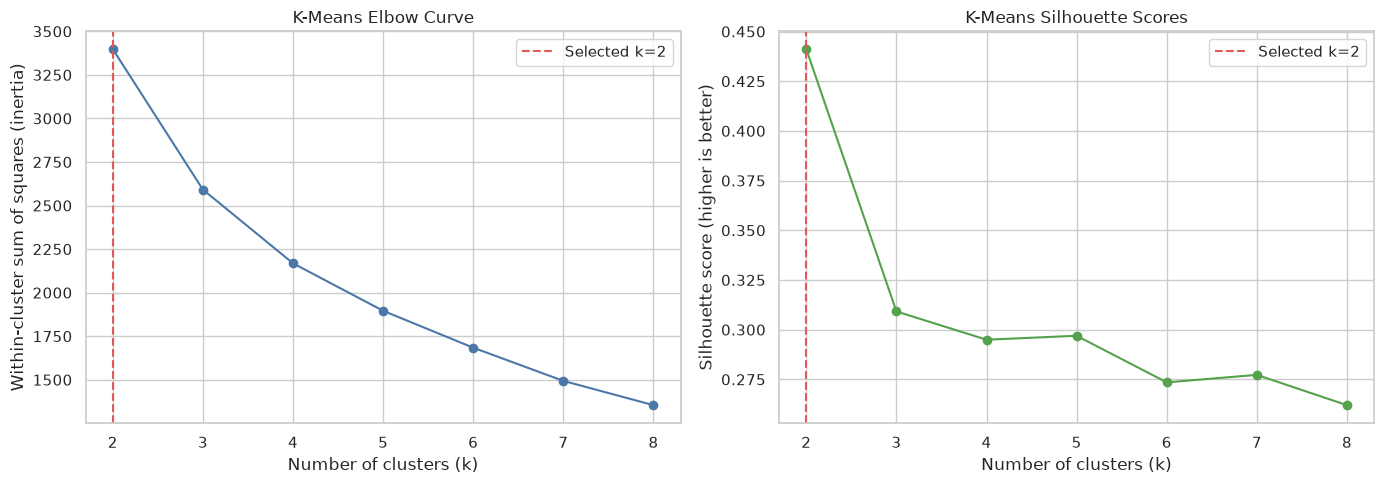

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
scaled_summary = pd.DataFrame(
    {"Feature": FEATURES, "Scaled mean": X_scaled.mean(axis=0), "Scaled standard deviation": X_scaled.std(axis=0)}
)
display(scaled_summary)
assert np.isfinite(X_scaled).all()
assert np.allclose(X_scaled.mean(axis=0), 0.0, atol=1e-12)
assert np.allclose(X_scaled.std(axis=0), 1.0, atol=1e-12)


def internal_metrics(features, labels):
    return {
        "Silhouette Score": silhouette_score(features, labels),
        "Davies-Bouldin Index": davies_bouldin_score(features, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(features, labels),
    }


K_CANDIDATES = list(range(2, 9))
kmeans_search_rows = []
for k in K_CANDIDATES:
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)
    kmeans_search_rows.append({"k": k, "Inertia": model.inertia_, **internal_metrics(X_scaled, labels)})
kmeans_search = pd.DataFrame(kmeans_search_rows)
SELECTED_K = int(kmeans_search.loc[kmeans_search["Silhouette Score"].idxmax(), "k"])
display(kmeans_search.style.format({
    "Inertia": "{:.2f}", "Silhouette Score": "{:.4f}",
    "Davies-Bouldin Index": "{:.4f}", "Calinski-Harabasz Index": "{:.2f}",
}))
print(f"Selected k from the highest label-free silhouette: {SELECTED_K}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(kmeans_search["k"], kmeans_search["Inertia"], marker="o", color="#4C78A8")
axes[0].axvline(SELECTED_K, color="#E45756", linestyle="--", label=f"Selected k={SELECTED_K}")
axes[0].set_title("K-Means Elbow Curve")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Within-cluster sum of squares (inertia)")
axes[0].legend()
axes[1].plot(kmeans_search["k"], kmeans_search["Silhouette Score"], marker="o", color="#54A24B")
axes[1].axvline(SELECTED_K, color="#E45756", linestyle="--", label=f"Selected k={SELECTED_K}")
axes[1].set_title("K-Means Silhouette Scores")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score (higher is better)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. K-Means final solution and hierarchical linkage comparison

The selected K-Means solution and all three hierarchical linkages use the same scaled features and selected k. A linkage is first required to have no cluster smaller than 5% of the observations. Among eligible linkages, the final choice is the highest silhouette score. This prevents a high silhouette caused only by isolating a handful of outliers, while retaining Davies-Bouldin and Calinski-Harabasz values for the full trade-off.

In [4]:
kmeans_model = KMeans(n_clusters=SELECTED_K, n_init=20, random_state=RANDOM_STATE)
kmeans_labels = kmeans_model.fit_predict(X_scaled)
kmeans_metrics = {
    "Algorithm": "K-Means",
    "Configuration": f"k={SELECTED_K}, n_init=20",
    **internal_metrics(X_scaled, kmeans_labels),
}
display(pd.Series(kmeans_labels).value_counts().sort_index().to_frame("K-Means rows"))

MIN_CLUSTER_SHARE = 0.05
LINKAGES = ["ward", "complete", "average"]
hierarchical_labels = {}
hierarchical_rows = []
for linkage_name in LINKAGES:
    labels = AgglomerativeClustering(n_clusters=SELECTED_K, linkage=linkage_name).fit_predict(X_scaled)
    cluster_sizes = pd.Series(labels).value_counts()
    hierarchical_labels[linkage_name] = labels
    hierarchical_rows.append(
        {
            "Linkage": linkage_name.title(),
            "Smallest Cluster Rows": int(cluster_sizes.min()),
            "Smallest Cluster Share": cluster_sizes.min() / len(labels),
            **internal_metrics(X_scaled, labels),
        }
    )
hierarchical_comparison = (
    pd.DataFrame(hierarchical_rows)
    .sort_values("Silhouette Score", ascending=False)
    .reset_index(drop=True)
)
eligible_hierarchical = hierarchical_comparison.loc[
    hierarchical_comparison["Smallest Cluster Share"] >= MIN_CLUSTER_SHARE
].reset_index(drop=True)
if eligible_hierarchical.empty:
    raise RuntimeError("No hierarchical linkage met the non-degeneracy threshold.")
SELECTED_LINKAGE = eligible_hierarchical.iloc[0]["Linkage"].lower()
hierarchical_final_labels = hierarchical_labels[SELECTED_LINKAGE]
display(hierarchical_comparison.style.format({
    "Smallest Cluster Share": "{:.2%}",
    "Silhouette Score": "{:.4f}",
    "Davies-Bouldin Index": "{:.4f}",
    "Calinski-Harabasz Index": "{:.2f}",
}))
print(f"Minimum eligible cluster share: {MIN_CLUSTER_SHARE:.0%}")
print(f"Selected eligible linkage by highest label-free silhouette: {SELECTED_LINKAGE}")

hierarchical_metrics = {
    "Algorithm": "Agglomerative Hierarchical",
    "Configuration": f"linkage={SELECTED_LINKAGE}, k={SELECTED_K}",
    **internal_metrics(X_scaled, hierarchical_final_labels),
}
clustering_comparison = pd.DataFrame([kmeans_metrics, hierarchical_metrics])
display(clustering_comparison.style.format({
    "Silhouette Score": "{:.4f}", "Davies-Bouldin Index": "{:.4f}", "Calinski-Harabasz Index": "{:.2f}",
}))

,K-Means rows
0,649
1,251


,Linkage,Smallest Cluster Rows,Smallest Cluster Share,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Average,6,0.67%,0.6219,0.4551,67.91
1,Complete,118,13.11%,0.4762,0.7975,546.67
2,Ward,426,47.33%,0.3104,1.1030,544.30


Minimum eligible cluster share: 5%
Selected eligible linkage by highest label-free silhouette: complete


,Algorithm,Configuration,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,"k=2, n_init=20",0.4411,0.9101,767.00
1,Agglomerative Hierarchical,"linkage=complete, k=2",0.4762,0.7975,546.67


**Metric guide:** Higher silhouette and Calinski-Harabasz indicate stronger internal structure under their definitions; lower Davies-Bouldin is better. A linkage with a cluster below 5% of the 900 records is treated as a degenerate candidate for this two-cluster presentation and is not eligible for selection. The table keeps every linkage visible so this safeguard and its trade-off can be examined.

## 5. Dendrogram from all observations

The hierarchy is calculated from the full 900-row scaled matrix. The rendered tree is truncated only for visual readability, not because a subset was fitted.

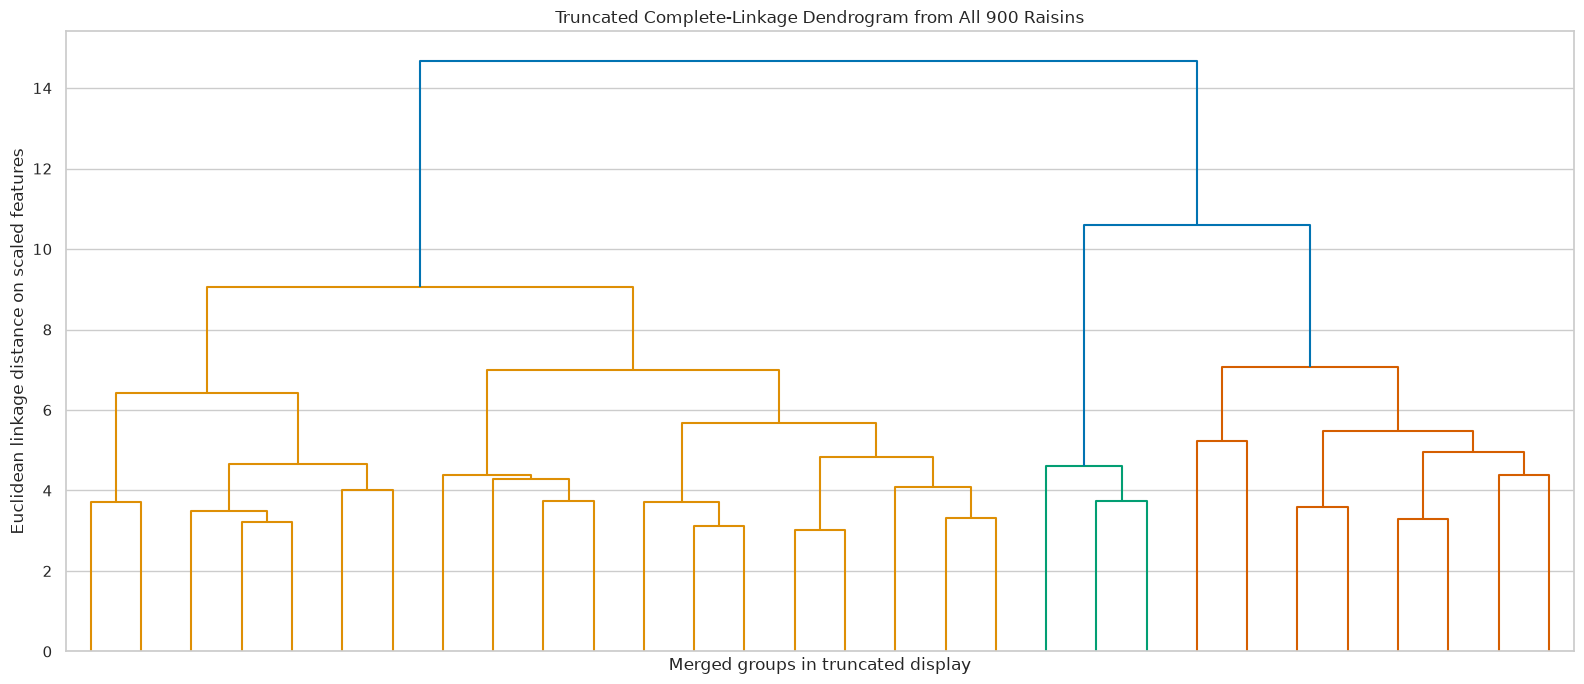

In [5]:
hierarchy_matrix = linkage(X_scaled, method=SELECTED_LINKAGE, metric="euclidean")
plt.figure(figsize=(16, 7))
dendrogram(
    hierarchy_matrix,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    no_labels=True,
)
plt.title(f"Truncated {SELECTED_LINKAGE.title()}-Linkage Dendrogram from All 900 Raisins")
plt.xlabel("Merged groups in truncated display")
plt.ylabel("Euclidean linkage distance on scaled features")
plt.tight_layout()
plt.show()

**Dendrogram interpretation:** The lower branches show compact merges at small distances, while taller late merges represent more dissimilar groups. This graphic uses all observations in linkage construction; truncation displays only the final 30 aggregate leaves so the hierarchy can be inspected at presentation scale.

## 6. Mandatory PCA visualisations and t-SNE visualisation

PCA and t-SNE receive only the scaled morphology matrix. Cluster labels, rather than the hidden reference variety, control every plotted color.

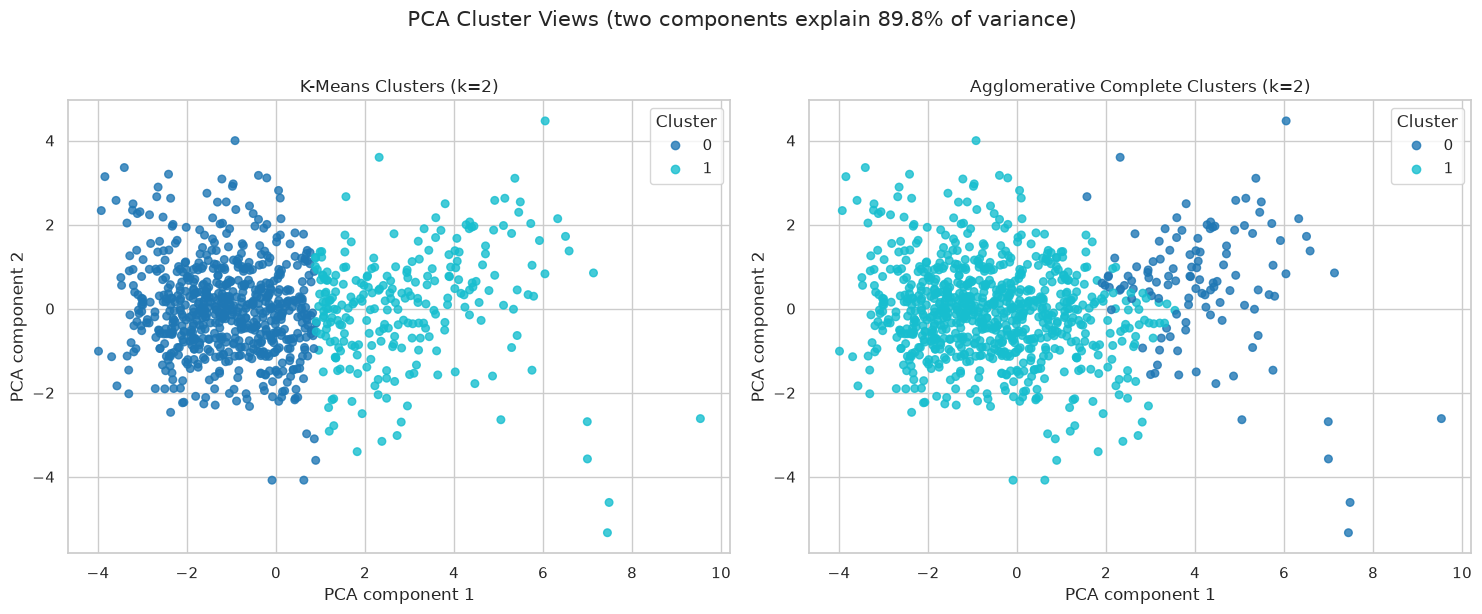

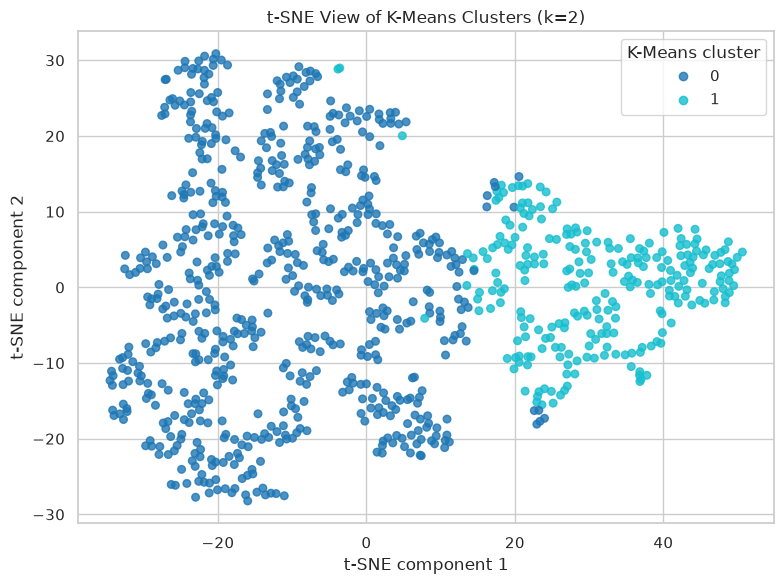

In [6]:
pca = PCA(n_components=2, svd_solver="full")
X_pca = pca.fit_transform(X_scaled)
pca_explained = 100 * pca.explained_variance_ratio_.sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_specs = [
    (kmeans_labels, f"K-Means Clusters (k={SELECTED_K})"),
    (hierarchical_final_labels, f"Agglomerative {SELECTED_LINKAGE.title()} Clusters (k={SELECTED_K})"),
]
for axis, (labels, title) in zip(axes, plot_specs):
    scatter = axis.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", s=30, alpha=0.8)
    axis.set_title(title)
    axis.set_xlabel("PCA component 1")
    axis.set_ylabel("PCA component 2")
    axis.legend(*scatter.legend_elements(), title="Cluster", loc="best")
fig.suptitle(f"PCA Cluster Views (two components explain {pca_explained:.1f}% of variance)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", max_iter=1000, random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_scaled)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels, cmap="tab10", s=30, alpha=0.8)
plt.title(f"t-SNE View of K-Means Clusters (k={SELECTED_K})")
plt.xlabel("t-SNE component 1")
plt.ylabel("t-SNE component 2")
plt.legend(*scatter.legend_elements(), title="K-Means cluster", loc="best")
plt.tight_layout()
plt.show()

**Visualisation caution:** PCA emphasizes large linear variance directions, while t-SNE emphasizes local neighborhoods. Neither chart is used as a hidden selection criterion. They help communicate the already selected label-free cluster assignments and may visually compress or exaggerate distances.

## 7. Post-hoc reference interpretation and morphology profiles

Only now, after k and linkage have been frozen, the supplied `Class` field is used to describe reference-label agreement. It does not retroactively change any model or selection result.

In [7]:
reference_counts = y_reference.value_counts().sort_index().to_frame("Rows")
reference_counts["Share pct"] = 100 * reference_counts["Rows"] / len(y_reference)
reference_interpretation = pd.DataFrame([
    {"Algorithm": "K-Means", "Adjusted Rand Index against Class": adjusted_rand_score(y_reference, kmeans_labels), "Normalized mutual information against Class": normalized_mutual_info_score(y_reference, kmeans_labels)},
    {"Algorithm": "Agglomerative Hierarchical", "Adjusted Rand Index against Class": adjusted_rand_score(y_reference, hierarchical_final_labels), "Normalized mutual information against Class": normalized_mutual_info_score(y_reference, hierarchical_final_labels)},
])
kmeans_reference_table = pd.crosstab(pd.Series(kmeans_labels, name="K-Means cluster"), y_reference, normalize="index")
hierarchical_reference_table = pd.crosstab(pd.Series(hierarchical_final_labels, name="Hierarchical cluster"), y_reference, normalize="index")
kmeans_profiles = X_raw.assign(Cluster=kmeans_labels).groupby("Cluster")[FEATURES].mean()
hierarchical_profiles = X_raw.assign(Cluster=hierarchical_final_labels).groupby("Cluster")[FEATURES].mean()

display(reference_counts)
display(reference_interpretation.style.format({"Adjusted Rand Index against Class": "{:.4f}", "Normalized mutual information against Class": "{:.4f}"}))
display(kmeans_reference_table.style.format("{:.2%}"))
display(hierarchical_reference_table.style.format("{:.2%}"))
display(kmeans_profiles)
display(hierarchical_profiles)

,Rows,Share pct
Class,,
Besni,450,50.0000
Kecimen,450,50.0000


,Algorithm,Adjusted Rand Index against Class,Normalized mutual information against Class
0,K-Means,0.2862,0.3377
1,Agglomerative Hierarchical,0.0637,0.1643


Class,Besni,Kecimen
K-Means cluster,,
0,31.43%,68.57%
1,98.01%,1.99%


Class,Besni,Kecimen
Hierarchical cluster,,
0,98.31%,1.69%
1,42.71%,57.29%


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
Cluster,,,,,,,
0,"67,954.4345",373.3881,233.0096,0.7615,"70,513.5686",0.7016,"1,029.4946"
1,"139,128.6335",579.7134,310.0242,0.8334,"144,638.1474",0.6941,"1,518.6214"


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
Cluster,,,,,,,
0,"165,452.8305",631.5977,342.5888,0.8240,"172,404.4407",0.7042,"1,661.4891"
1,"76,087.3159",400.6502,241.1942,0.7751,"78,930.6355",0.6988,"1,091.1256"


**Post-hoc interpretation rule:** Adjusted Rand Index, normalized mutual information, composition tables, and mean profiles are descriptive after-the-fact evidence only. A cluster can overlap a supplied variety class without proving a biological identity, and profile differences are associations rather than causal morphology mechanisms.

## 8. Final conclusion and reproducible exports

In [8]:
kmeans_row = clustering_comparison.set_index("Algorithm").loc["K-Means"]
hierarchical_row = clustering_comparison.set_index("Algorithm").loc["Agglomerative Hierarchical"]
best_internal_algorithm = clustering_comparison.sort_values("Silhouette Score", ascending=False).iloc[0]["Algorithm"]
display(Markdown(
    f"The label-free search selected `k={SELECTED_K}` and `{SELECTED_LINKAGE}` linkage. "
    f"K-Means: silhouette `{kmeans_row['Silhouette Score']:.4f}`, Davies-Bouldin `{kmeans_row['Davies-Bouldin Index']:.4f}`, and Calinski-Harabasz `{kmeans_row['Calinski-Harabasz Index']:.2f}`. "
    f"Agglomerative Hierarchical: silhouette `{hierarchical_row['Silhouette Score']:.4f}`, Davies-Bouldin `{hierarchical_row['Davies-Bouldin Index']:.4f}`, and Calinski-Harabasz `{hierarchical_row['Calinski-Harabasz Index']:.2f}`. "
    f"By silhouette, `{best_internal_algorithm}` has the stronger final internal separation. Reference-label evidence was computed only afterward."
))

kmeans_search.to_csv(RESULTS_DIR / "clustering_kmeans_search.csv", index=False)
hierarchical_comparison.to_csv(RESULTS_DIR / "clustering_hierarchical_linkage_comparison.csv", index=False)
clustering_comparison.to_csv(RESULTS_DIR / "clustering_model_comparison.csv", index=False)
reference_interpretation.to_csv(RESULTS_DIR / "clustering_reference_interpretation.csv", index=False)
print("Exported clustering search, linkage comparison, final comparison, and post-hoc reference tables.")

The label-free search selected `k=2` and `complete` linkage. K-Means: silhouette `0.4411`, Davies-Bouldin `0.9101`, and Calinski-Harabasz `767.00`. Agglomerative Hierarchical: silhouette `0.4762`, Davies-Bouldin `0.7975`, and Calinski-Harabasz `546.67`. By silhouette, `Agglomerative Hierarchical` has the stronger final internal separation. Reference-label evidence was computed only afterward.

Exported clustering search, linkage comparison, final comparison, and post-hoc reference tables.


**Limitations:** The image-derived morphology measures can reflect correlated size variables and the source image-processing procedure. Internal metrics quantify geometric separation, not usefulness in a real grading process. The two supplied varieties are a limited reference and cannot prove that a cluster is a definitive variety identity. Instructor confirmation of this proposed dataset is still required.